In [1]:
#
# This is a sample Notebook to demonstrate how to read "MNIST Dataset"
#
import numpy as np # linear algebra
import struct
from array import array
from os.path  import join

#
# MNIST Data Loader Class
#
class MnistDataloader(object):
    def __init__(self, training_images_filepath,training_labels_filepath,
                 test_images_filepath, test_labels_filepath):
        self.training_images_filepath = training_images_filepath
        self.training_labels_filepath = training_labels_filepath
        self.test_images_filepath = test_images_filepath
        self.test_labels_filepath = test_labels_filepath
    
    def read_images_labels(self, images_filepath, labels_filepath):        
        labels = []
        with open(labels_filepath, 'rb') as file:
            magic, size = struct.unpack(">II", file.read(8))
            if magic != 2049:
                raise ValueError('Magic number mismatch, expected 2049, got {}'.format(magic))
            labels = array("B", file.read())        
        
        with open(images_filepath, 'rb') as file:
            magic, size, rows, cols = struct.unpack(">IIII", file.read(16))
            if magic != 2051:
                raise ValueError('Magic number mismatch, expected 2051, got {}'.format(magic))
            image_data = array("B", file.read())        
        images = []
        for i in range(size):
            images.append([0] * rows * cols)
        for i in range(size):
            img = np.array(image_data[i * rows * cols:(i + 1) * rows * cols])
            img = img.reshape(28, 28)
            images[i][:] = img            
        
        return images, labels
            
    def load_data(self):
        x_train, y_train = self.read_images_labels(self.training_images_filepath, self.training_labels_filepath)
        x_test, y_test = self.read_images_labels(self.test_images_filepath, self.test_labels_filepath)
        return (x_train, y_train),(x_test, y_test)        



In [2]:
#
# Download MNIST Dataset using torchvision
#
import os
import shutil
import torchvision
import torchvision.datasets as datasets

# Create input directory structure
input_path = 'input/'
os.makedirs(input_path, exist_ok=True)

# Download MNIST using torchvision (this will download to ~/.cache/torch/vision/)
print('Downloading MNIST dataset using torchvision...')
try:
    # Download training set
    train_dataset = datasets.MNIST(root='../data', train=True, download=True)
    # Download test set
    test_dataset = datasets.MNIST(root='../data', train=False, download=True)
    
    # Get the raw data directory (torchvision stores it in a specific location)
    raw_data_dir = os.path.join(os.path.expanduser('~'), '.cache', 'torch', 'vision', 'MNIST', 'raw')
    
    if not os.path.exists(raw_data_dir):
        # Alternative location
        raw_data_dir = os.path.join('../data', 'MNIST', 'raw')
    
    if os.path.exists(raw_data_dir):
        print(f'Found MNIST raw files in: {raw_data_dir}')
        
        # Create subdirectories and copy files
        files_to_copy = {
            'train-images-idx3-ubyte': 'train-images-idx3-ubyte',
            'train-labels-idx1-ubyte': 'train-labels-idx1-ubyte',
            't10k-images-idx3-ubyte': 't10k-images-idx3-ubyte',
            't10k-labels-idx1-ubyte': 't10k-labels-idx1-ubyte'
        }
        
        for subdir_name, filename in files_to_copy.items():
            subdir = os.path.join(input_path, subdir_name)
            os.makedirs(subdir, exist_ok=True)
            
            source_file = os.path.join(raw_data_dir, filename)
            dest_file = os.path.join(subdir, filename)
            
            if os.path.exists(source_file):
                if not os.path.exists(dest_file):
                    shutil.copy2(source_file, dest_file)
                    print(f'Copied {filename} to {dest_file}')
                else:
                    print(f'{filename} already exists, skipping.')
            else:
                print(f'Warning: {source_file} not found')
        
        print('\nMNIST dataset download and setup complete!')
    else:
        print(f'Error: Could not find raw data directory at {raw_data_dir}')
        print('Please check if torchvision downloaded the files correctly.')
        
except Exception as e:
    print(f'Error downloading with torchvision: {e}')
    print('Trying alternative download method...')
    
    # Fallback: try direct download from alternative source
    import urllib.request
    import gzip
    
    # Alternative URLs (using a mirror)
    mnist_urls = {
        'train-images-idx3-ubyte': 'https://storage.googleapis.com/cvdf-datasets/mnist/train-images-idx3-ubyte.gz',
        'train-labels-idx1-ubyte': 'https://storage.googleapis.com/cvdf-datasets/mnist/train-labels-idx1-ubyte.gz',
        't10k-images-idx3-ubyte': 'https://storage.googleapis.com/cvdf-datasets/mnist/t10k-images-idx3-ubyte.gz',
        't10k-labels-idx1-ubyte': 'https://storage.googleapis.com/cvdf-datasets/mnist/t10k-labels-idx1-ubyte.gz'
    }
    
    def download_and_extract(url, output_dir, filename):
        """Download and extract a gzipped file"""
        filepath = os.path.join(output_dir, filename)
        gz_filepath = filepath + '.gz'
        
        # Skip if already exists
        if os.path.exists(filepath):
            print(f'{filename} already exists, skipping download.')
            return
        
        print(f'Downloading {filename}...')
        try:
            urllib.request.urlretrieve(url, gz_filepath)
            
            print(f'Extracting {filename}...')
            with gzip.open(gz_filepath, 'rb') as f_in:
                with open(filepath, 'wb') as f_out:
                    shutil.copyfileobj(f_in, f_out)
            
            # Remove the .gz file
            os.remove(gz_filepath)
            print(f'{filename} downloaded and extracted successfully.')
        except Exception as e:
            print(f'Error downloading {filename}: {e}')
            if os.path.exists(gz_filepath):
                os.remove(gz_filepath)
    
    # Download all MNIST files
    for filename, url in mnist_urls.items():
        # Create subdirectory for each file type
        subdir = os.path.join(input_path, filename)
        os.makedirs(subdir, exist_ok=True)
        
        # Download to subdirectory
        download_and_extract(url, subdir, filename)
    
    print('\nMNIST dataset download complete!')


Found MNIST raw files in: ../data/MNIST/raw
train-images-idx3-ubyte already exists, skipping.
train-labels-idx1-ubyte already exists, skipping.
t10k-images-idx3-ubyte already exists, skipping.
t10k-labels-idx1-ubyte already exists, skipping.

MNIST dataset download and setup complete!


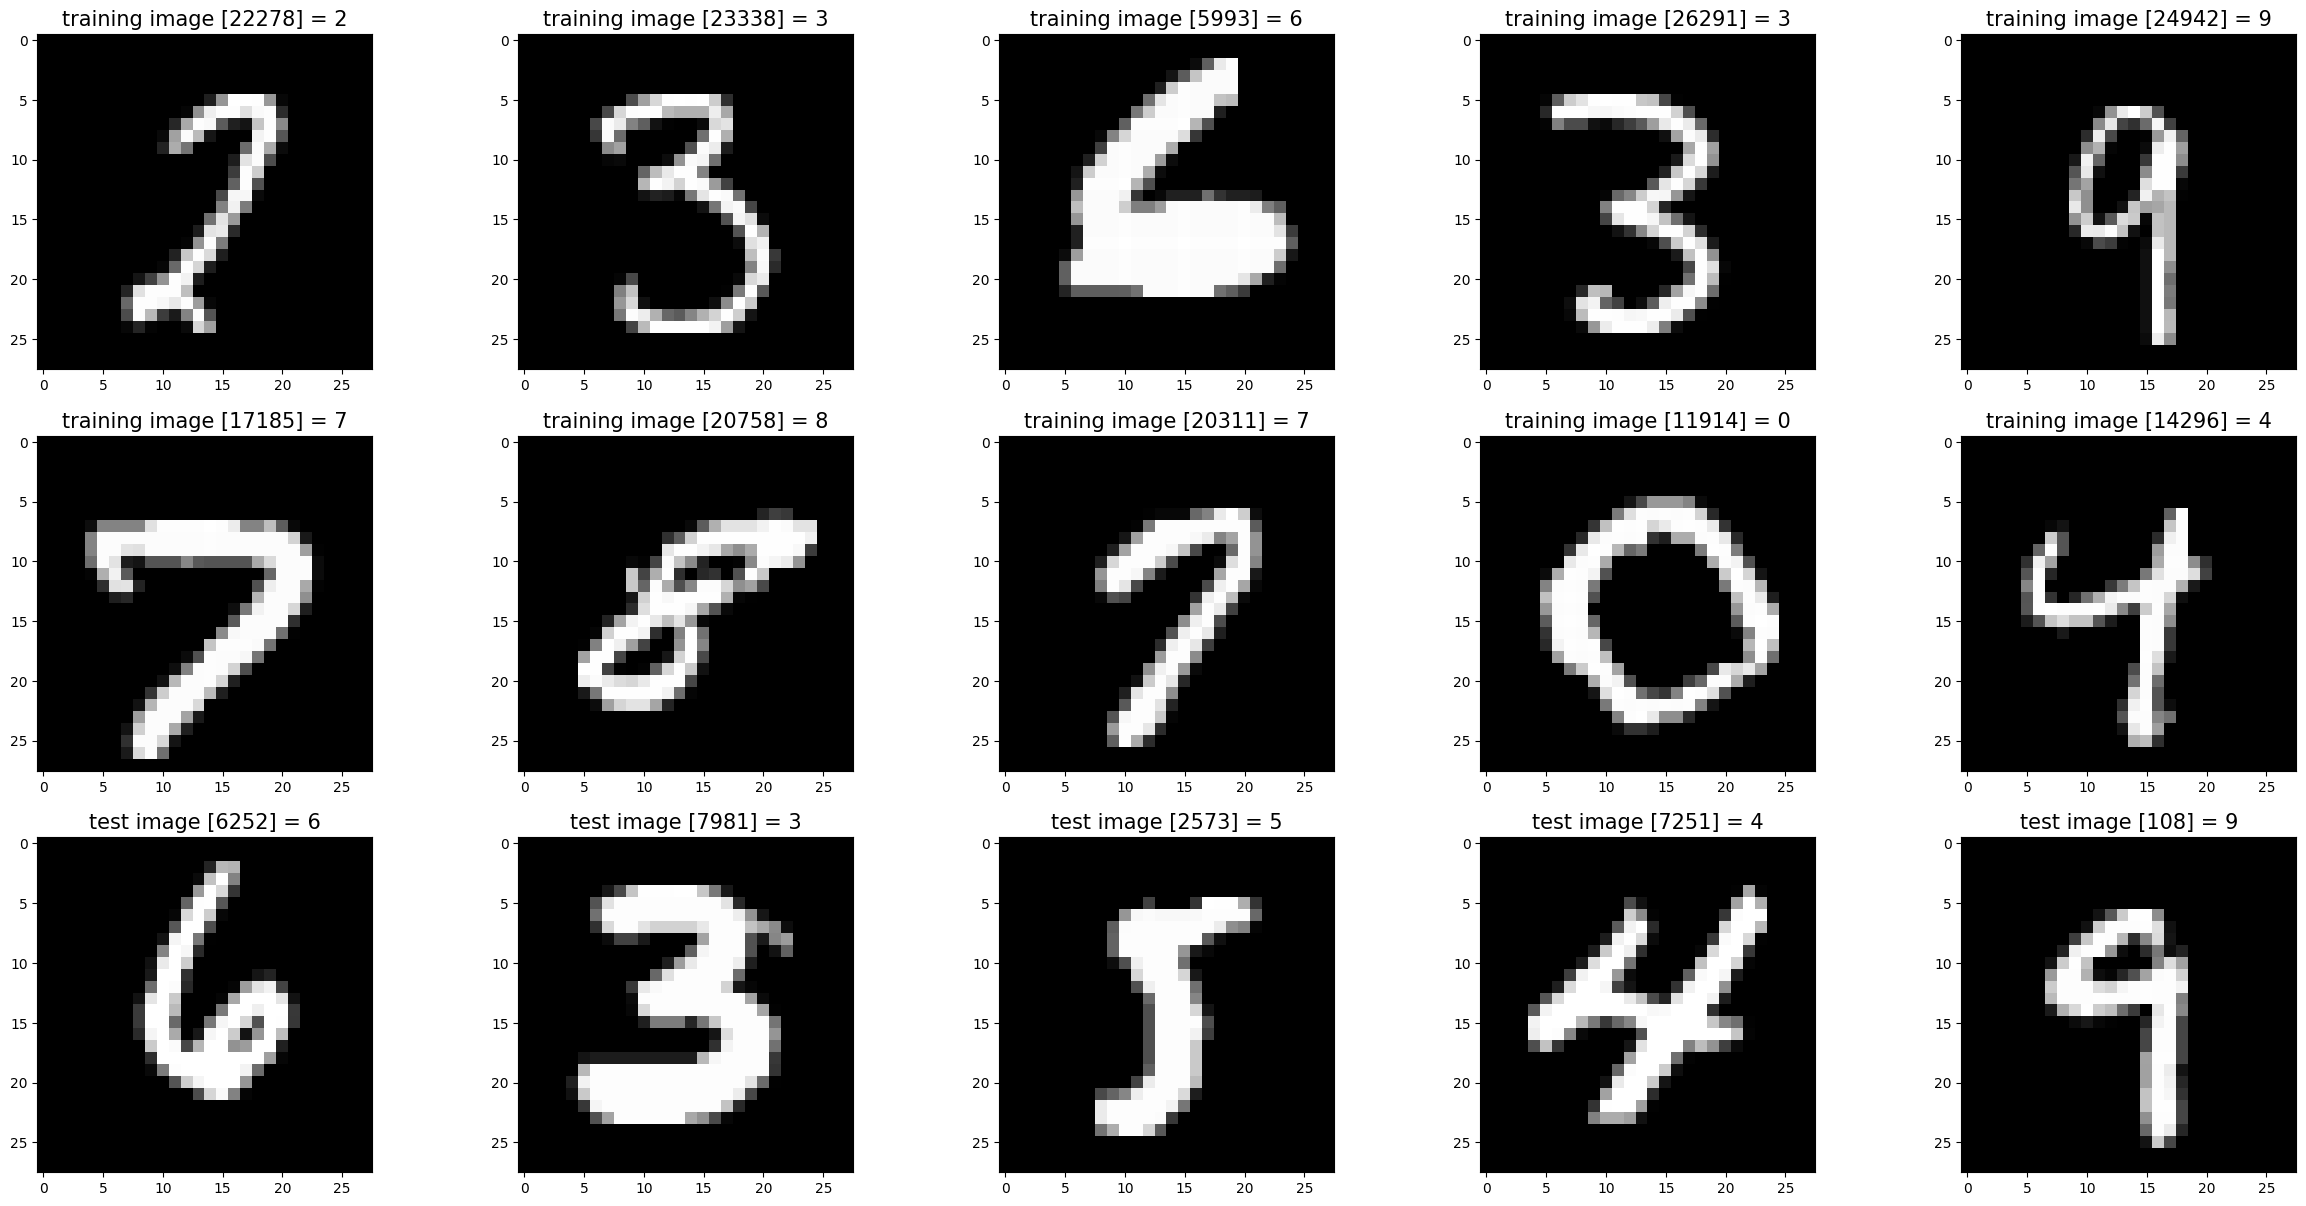

In [3]:
#
# Verify Reading Dataset via MnistDataloader class
#
%matplotlib inline
import random
import matplotlib.pyplot as plt

#
# Set file paths based on added MNIST Datasets
#
input_path = 'input/'
training_images_filepath = join(input_path, 'train-images-idx3-ubyte/train-images-idx3-ubyte')
training_labels_filepath = join(input_path, 'train-labels-idx1-ubyte/train-labels-idx1-ubyte')
test_images_filepath = join(input_path, 't10k-images-idx3-ubyte/t10k-images-idx3-ubyte')
test_labels_filepath = join(input_path, 't10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte')

#
# Helper function to show a list of images with their relating titles
#
def show_images(images, title_texts):
    cols = 5
    rows = int(len(images)/cols) + 1
    plt.figure(figsize=(30,20))
    index = 1    
    for x in zip(images, title_texts):        
        image = x[0]        
        title_text = x[1]
        plt.subplot(rows, cols, index)        
        plt.imshow(image, cmap=plt.cm.gray)
        if (title_text != ''):
            plt.title(title_text, fontsize = 15);        
        index += 1

#
# Load MINST dataset
#
mnist_dataloader = MnistDataloader(training_images_filepath, training_labels_filepath, test_images_filepath, test_labels_filepath)
(x_train, y_train), (x_test, y_test) = mnist_dataloader.load_data()

#
# Show some random training and test images 
#
images_2_show = []
titles_2_show = []
for i in range(0, 10):
    r = random.randint(1, 60000)
    images_2_show.append(x_train[r])
    titles_2_show.append('training image [' + str(r) + '] = ' + str(y_train[r]))    

for i in range(0, 5):
    r = random.randint(1, 10000)
    images_2_show.append(x_test[r])        
    titles_2_show.append('test image [' + str(r) + '] = ' + str(y_test[r]))    

show_images(images_2_show, titles_2_show)

[array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8), array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8), array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8), array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8), array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8), array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0, 23, 59, 59, 59, 27,  0,  0,  0,  0,  0], dtype=uint8), array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   5,  65, 118, 207, 229, 254, 253, 253, 232, 177,   0,   0,
         0,   0], dtype=uint8), array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        31, 194, 253, 253, 253, 253, 254, 253

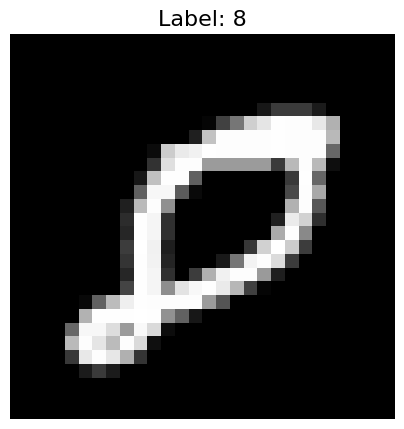

In [4]:
#
# Show a single image
#
import matplotlib.pyplot as plt
import random

index = 49543 
image = x_train[index]
print(image)
label = y_train[index]

# Display the single image
plt.figure(figsize=(5, 5))
plt.imshow(image, cmap=plt.cm.gray)
plt.title(f'Label: {label}', fontsize=16)
plt.axis('off')
plt.show()


In [5]:
#
# Function to convert batch of images to binary 1D vectors
#
import numpy as np

def convert_binary(images, labels, threshold=127):
    """
    Convert a batch of images to binary 1D vectors.
    
    Parameters:
    -----------
    images : list or array-like
        List of input images (each can be list or numpy array)
    labels : list or array-like
        List of labels corresponding to each image (for reference, not used in conversion)
    threshold : int, optional
        Threshold value for binary conversion (default: 127)
        Pixels > threshold become 1, else 0
    
    Returns:
    --------
    numpy.ndarray
        2D binary array with shape (batch_size, 784) where each row is a binary 1D vector
    """
    batch_size = len(images)
    binary_batch = []
    
    # Process each image in the batch
    for i, image in enumerate(images):
        # Convert to numpy array if it's not already
        if isinstance(image, list):
            image = np.array(image)
        
        # Convert to binary: threshold (pixels > threshold become 1, else 0)
        # This makes white/light pixels = 1, black/dark pixels = 0
        binary_image = (image > threshold).astype(int)
        
        # Flatten the 2D binary array into a 1D vector
        binary_1d = binary_image.flatten()
        
        binary_batch.append(binary_1d)
    
    # Convert list to numpy array: shape will be (batch_size, 784)
    return np.array(binary_batch)

# Example usage with single image
index = 49543
image = x_train[index]
label = y_train[index]

# Convert single image (pass as list)
binary_vector = convert_binary([image], [label])
print("Single image conversion:")
print(f"Image label: {label}")
print(f"Binary batch shape: {binary_vector.shape}")
print(f"First 50 values of first image: {binary_vector[0][:50]}")
print(f"Data type: {binary_vector.dtype}")
print(f"Unique values: {np.unique(binary_vector)}")  # Should show [0, 1]

# Example usage with batch of images
print("\n" + "="*50)
print("Batch conversion example:")
batch_images = [x_train[0], x_train[1], x_train[2], x_train[3], x_train[4]]
batch_labels = [y_train[0], y_train[1], y_train[2], y_train[3], y_train[4]]

binary_batch = convert_binary(batch_images, batch_labels)
print(f"Batch size: {len(batch_images)}")
print(f"Binary batch shape: {binary_batch.shape}")
print(f"Labels: {batch_labels}")
print(f"First 20 values of first image: {binary_batch[0][:20]}")
print(f"First 20 values of second image: {binary_batch[1][:20]}")


Single image conversion:
Image label: 8
Binary batch shape: (1, 784)
First 50 values of first image: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0]
Data type: int64
Unique values: [0 1]

Batch conversion example:
Batch size: 5
Binary batch shape: (5, 784)
Labels: [5, 0, 4, 1, 9]
First 20 values of first image: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
First 20 values of second image: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [6]:
#
# Simple Neural Network using PyTorch
#
import torch
import torch.nn as nn

class SimpleNN(nn.Module):
    def __init__(self, input_size=784, hidden_size=128, num_classes=10):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, num_classes)
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

# Create model instance
model = SimpleNN()
print(model)

# Convert numpy array to PyTorch tensor
binary_batch_tensor = torch.FloatTensor(binary_batch)
y_output = model(binary_batch_tensor)

# Convert labels to tensor
labels_tensor = torch.LongTensor(batch_labels)

# Define loss function
criterion = nn.CrossEntropyLoss()

# Calculate loss
loss = criterion(y_output, labels_tensor)

_, predicted = torch.max(y_output.data, 1)
correct = (predicted == labels_tensor).sum().item()
accuracy = correct / len(batch_labels) * 100

# Print results
print(f"Output shape: {y_output.shape}")
print(f"Loss: {loss.item():.4f}")
print(f"Accuracy: {accuracy:.2f}%")
print(f"Predicted: {predicted.tolist()}")
print(f"Actual: {batch_labels}")

SimpleNN(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Output shape: torch.Size([5, 10])
Loss: 2.3438
Accuracy: 0.00%
Predicted: [8, 8, 8, 5, 5]
Actual: [5, 0, 4, 1, 9]


Preparing training data...


/var/folders/ny/321h18td74qbgkzyl41nt8740000gn/T/ipykernel_4218/2772407525.py:24: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:256.)
  train_images_tensor = torch.FloatTensor(train_images_binary)


Preparing test data...

Starting training for 5 epochs...
Training samples: 60000, Batch size: 64
--------------------------------------------------
Calculating initial loss (epoch 0)...
Epoch [0/5], Loss: 2.3060, Accuracy: 9.61%
--------------------------------------------------
Epoch [1/5], Loss: 0.3713, Accuracy: 89.85%
Epoch [2/5], Loss: 0.1766, Accuracy: 94.89%
Epoch [3/5], Loss: 0.1229, Accuracy: 96.42%
Epoch [4/5], Loss: 0.0917, Accuracy: 97.35%
Epoch [5/5], Loss: 0.0702, Accuracy: 98.00%
--------------------------------------------------
Training completed!
Plotting 6 loss values (Epoch 0 + 5 training epochs)


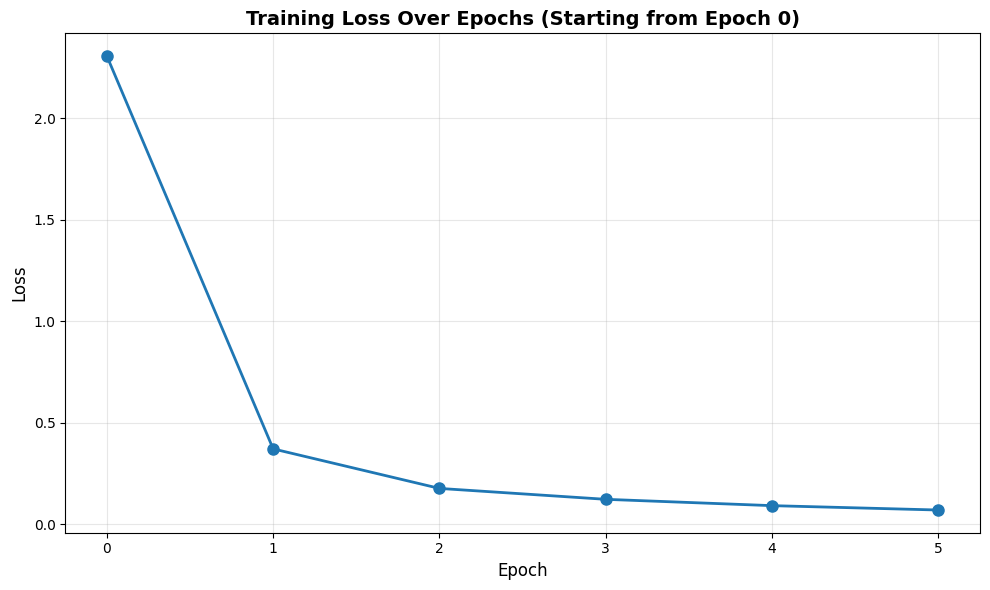


Loss values per epoch:
  Epoch 0 (before training): 2.3060
  Epoch 1: 0.3713
  Epoch 2: 0.1766
  Epoch 3: 0.1229
  Epoch 4: 0.0917
  Epoch 5: 0.0702

Evaluating on test set...
Test Loss: 0.0917
Test Accuracy: 96.70%


In [7]:
#
# Training Loop with Gradient Descent
#
import torch.optim as optim

# Prepare training data - convert to binary and normalize
print("Preparing training data...")
train_images_binary = []
train_labels_list = []

# Convert a subset for faster training (or use all 60000)
num_train_samples = 60000  # Use first 10000 samples for faster training
for i in range(num_train_samples):
    img = x_train[i]
    if isinstance(img, list):
        img = np.array(img)
    # Normalize to [0, 1]
    img_normalized = img / 255.0
    # Convert to binary
    binary_img = (img_normalized > 0.5).astype(np.float32)
    train_images_binary.append(binary_img.flatten())
    train_labels_list.append(y_train[i])

train_images_tensor = torch.FloatTensor(train_images_binary)
train_labels_tensor = torch.LongTensor(train_labels_list)

# Prepare test data
print("Preparing test data...")
test_images_binary = []
test_labels_list = []

num_test_samples = 1000  # Use first 1000 test samples
for i in range(num_test_samples):
    img = x_test[i]
    if isinstance(img, list):
        img = np.array(img)
    # Normalize to [0, 1]
    img_normalized = img / 255.0
    # Convert to binary
    binary_img = (img_normalized > 0.5).astype(np.float32)
    test_images_binary.append(binary_img.flatten())
    test_labels_list.append(y_test[i])

test_images_tensor = torch.FloatTensor(test_images_binary)
test_labels_tensor = torch.LongTensor(test_labels_list)

# Training parameters
batch_size = 64
learning_rate = 0.001
num_epochs = 5

# Define loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Training loop
print(f"\nStarting training for {num_epochs} epochs...")
print(f"Training samples: {num_train_samples}, Batch size: {batch_size}")
print("-" * 50)

# List to store loss for each epoch
epoch_losses = []

# Calculate initial loss (epoch 0) before training
print("Calculating initial loss (epoch 0)...")
model.eval()
initial_total_loss = 0
initial_correct = 0
initial_total = 0

with torch.no_grad():
    for i in range(0, num_train_samples, batch_size):
        batch_images = train_images_tensor[i:i+batch_size]
        batch_labels = train_labels_tensor[i:i+batch_size]
        
        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)
        
        initial_total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        initial_total += batch_labels.size(0)
        initial_correct += (predicted == batch_labels).sum().item()

initial_avg_loss = initial_total_loss / (num_train_samples // batch_size)
initial_accuracy = 100 * initial_correct / initial_total
epoch_losses.append(initial_avg_loss)

print(f"Epoch [0/{num_epochs}], Loss: {initial_avg_loss:.4f}, Accuracy: {initial_accuracy:.2f}%")
print("-" * 50)

for epoch in range(num_epochs):
    model.train()  # Set model to training mode
    total_loss = 0
    correct = 0
    total = 0
    
    # Mini-batch training
    for i in range(0, num_train_samples, batch_size):
        # Get batch
        batch_images = train_images_tensor[i:i+batch_size]
        batch_labels = train_labels_tensor[i:i+batch_size]
        
        # Forward pass
        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)
        
        # Backward pass and optimization
        optimizer.zero_grad()  # Clear gradients
        loss.backward()        # Compute gradients
        optimizer.step()       # Update weights
        
        # Statistics
        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += batch_labels.size(0)
        correct += (predicted == batch_labels).sum().item()
    
    # Calculate and store average loss for this epoch
    avg_loss = total_loss / (num_train_samples // batch_size)
    epoch_losses.append(avg_loss)
    
    accuracy = 100 * correct / total
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}, Accuracy: {accuracy:.2f}%")

print("-" * 50)
print("Training completed!")

# Plot training loss
import matplotlib.pyplot as plt

# Ensure we have the right number of epochs (should be num_epochs + 1 for epoch 0)
print(f"Plotting {len(epoch_losses)} loss values (Epoch 0 + {num_epochs} training epochs)")

plt.figure(figsize=(10, 6))
# Use len(epoch_losses) to match the number of loss values
epochs_range = list(range(len(epoch_losses)))
plt.plot(epochs_range, epoch_losses, marker='o', linewidth=2, markersize=8)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.title('Training Loss Over Epochs (Starting from Epoch 0)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xticks(epochs_range)
plt.tight_layout()
plt.show()

print(f"\nLoss values per epoch:")
print(f"  Epoch 0 (before training): {epoch_losses[0]:.4f}")
for i in range(1, len(epoch_losses)):
    print(f"  Epoch {i}: {epoch_losses[i]:.4f}")

# Evaluate on test set
print("\nEvaluating on test set...")
model.eval()  # Set model to evaluation mode
with torch.no_grad():
    test_outputs = model(test_images_tensor)
    test_loss = criterion(test_outputs, test_labels_tensor)
    _, test_predicted = torch.max(test_outputs.data, 1)
    test_correct = (test_predicted == test_labels_tensor).sum().item()
    test_accuracy = 100 * test_correct / num_test_samples
    
    print(f"Test Loss: {test_loss.item():.4f}")
    print(f"Test Accuracy: {test_accuracy:.2f}%")

# # Save model weights
# model_path = 'mnist_model_weights.pth'
# torch.save(model.state_dict(), model_path)
# print(f"\nModel weights saved to: {model_path}")

# # Optionally, save the entire model (includes architecture)
# full_model_path = 'mnist_model_full.pth'
# torch.save(model, full_model_path)
# print(f"Full model saved to: {full_model_path}")


DATA VALIDATION

Training Data:
  Number of samples: 60000
  Number of labels: 60000
  Image shape: (28, 28)
  Label range: 0 to 9
  Unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Test Data:
  Number of samples: 10000
  Number of labels: 10000
  Image shape: (28, 28)
  Label range: 0 to 9
  Unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Label Distribution (Training):
  Label 0: 5923 samples (9.87%)
  Label 1: 6742 samples (11.24%)
  Label 2: 5958 samples (9.93%)
  Label 3: 6131 samples (10.22%)
  Label 4: 5842 samples (9.74%)
  Label 5: 5421 samples (9.04%)
  Label 6: 5918 samples (9.86%)
  Label 7: 6265 samples (10.44%)
  Label 8: 5851 samples (9.75%)
  Label 9: 5949 samples (9.92%)

Label Distribution (Test):
  Label 0: 980 samples (9.80%)
  Label 1: 1135 samples (11.35%)
  Label 2: 1032 samples (10.32%)
  Label 3: 1010 samples (10.10%)
  Label 4: 982 samples (9.82%)
  Label 5: 892 samples (8.92%)
  Label 6: 958 samples (9.58%)
  Label 7: 1028 samples (10.28%)
  Label 8: 974 samples 

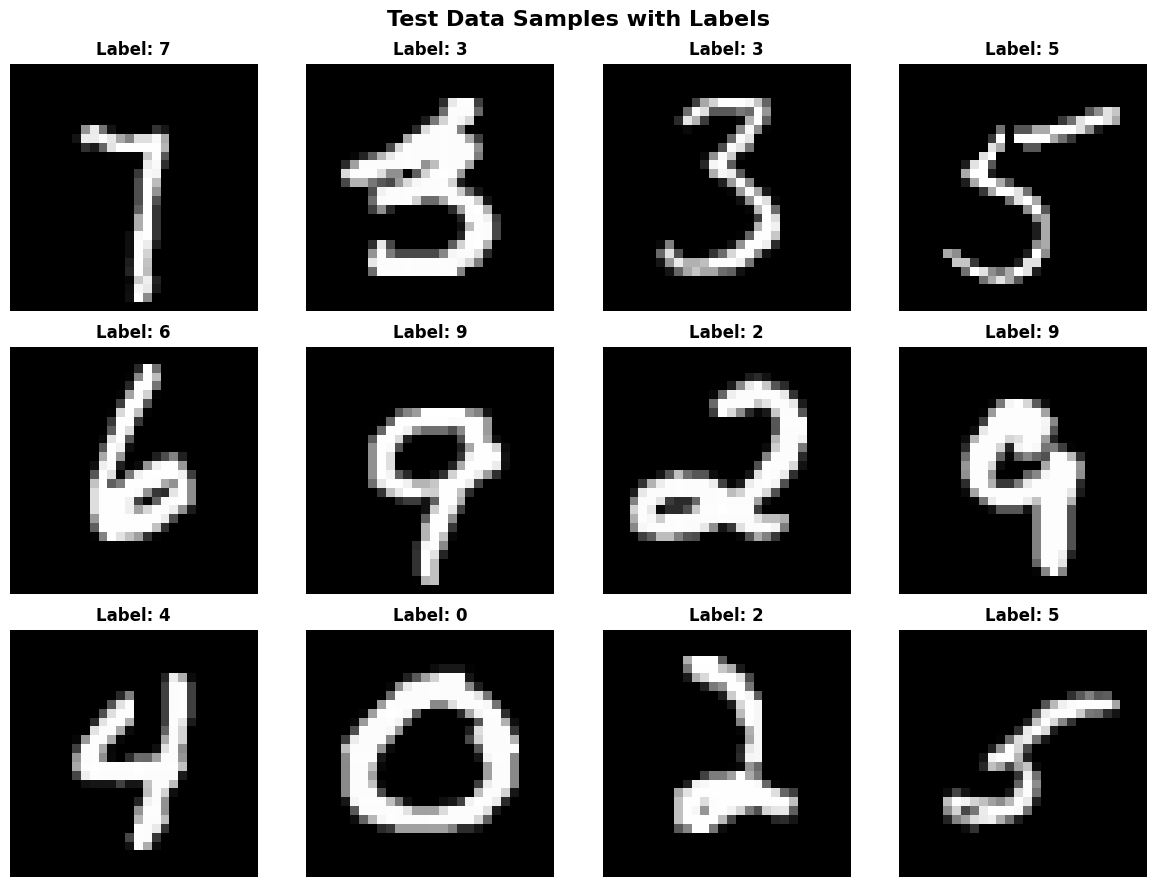


MODEL VALIDATION

Validation on 16 random test samples:
  Correct predictions: 16/16
  Accuracy: 100.00%


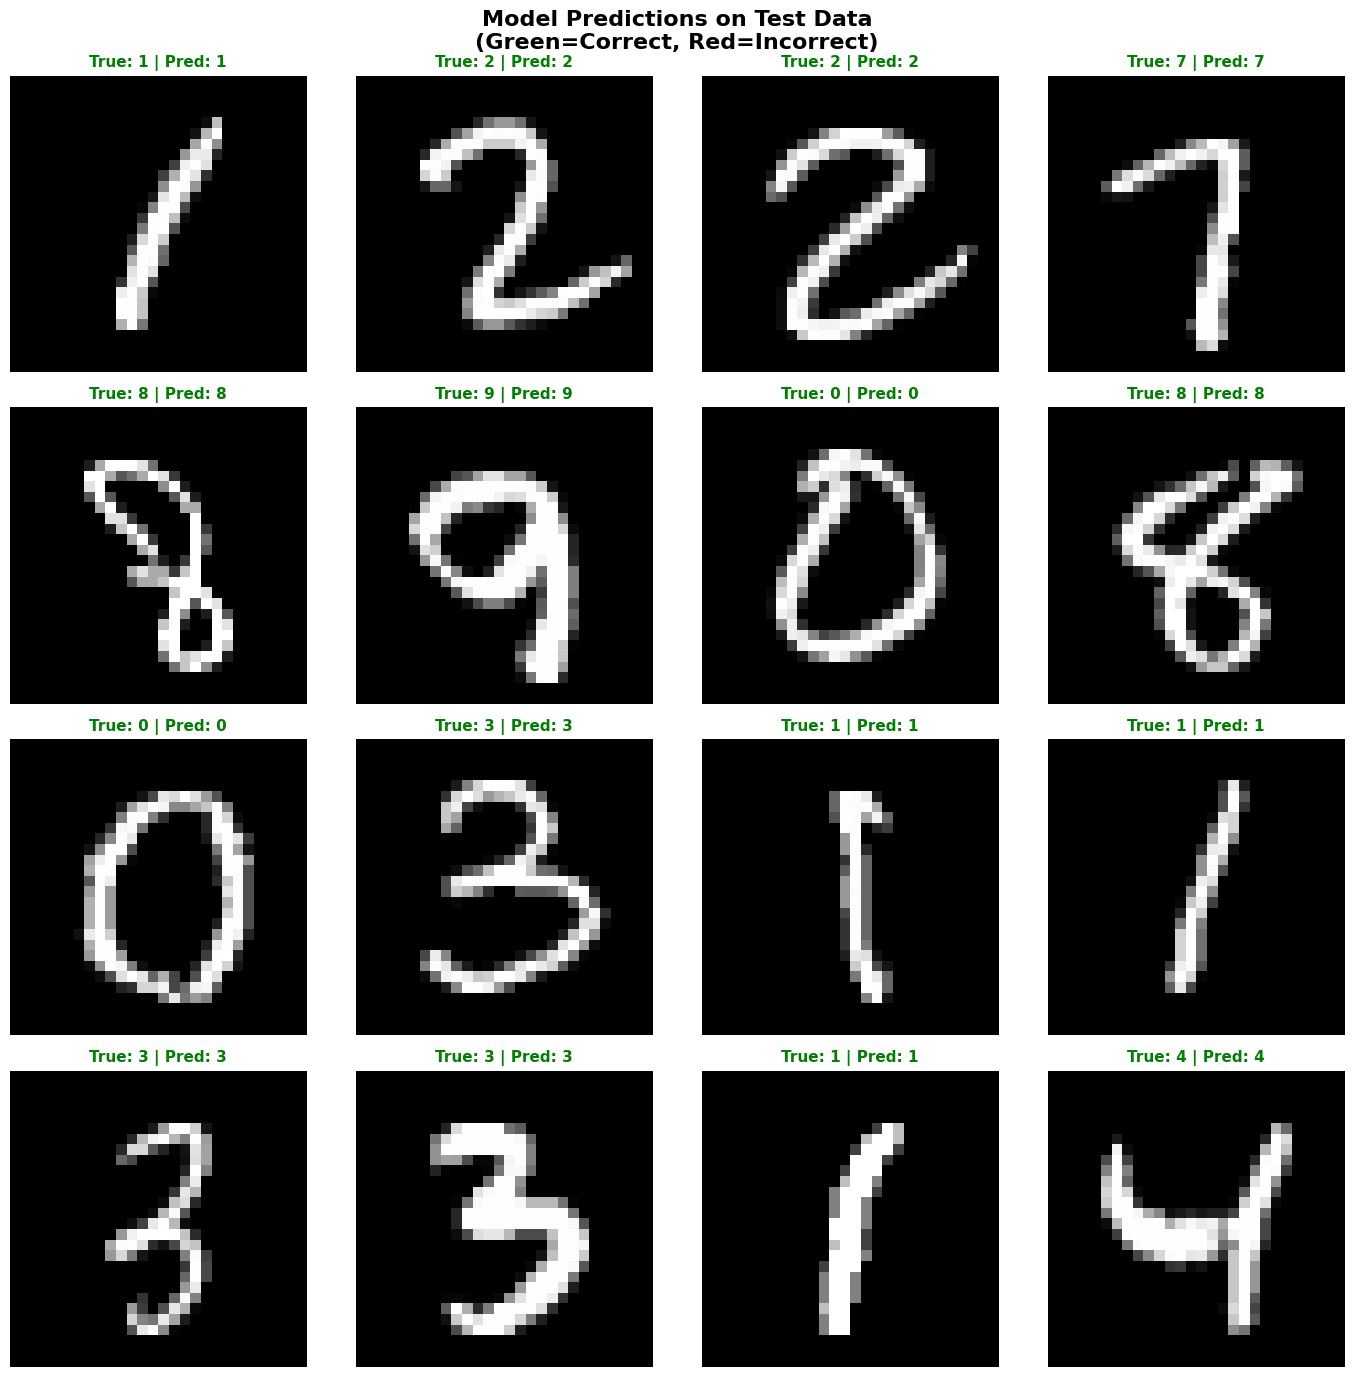


Detailed Results:
------------------------------------------------------------
  Sample  1: True=1, Predicted=1 ✓
  Sample  2: True=2, Predicted=2 ✓
  Sample  3: True=2, Predicted=2 ✓
  Sample  4: True=7, Predicted=7 ✓
  Sample  5: True=8, Predicted=8 ✓
  Sample  6: True=9, Predicted=9 ✓
  Sample  7: True=0, Predicted=0 ✓
  Sample  8: True=8, Predicted=8 ✓
  Sample  9: True=0, Predicted=0 ✓
  Sample 10: True=3, Predicted=3 ✓
  Sample 11: True=1, Predicted=1 ✓
  Sample 12: True=1, Predicted=1 ✓
  Sample 13: True=3, Predicted=3 ✓
  Sample 14: True=3, Predicted=3 ✓
  Sample 15: True=1, Predicted=1 ✓
  Sample 16: True=4, Predicted=4 ✓

OVERALL MODEL PERFORMANCE
Test Set Accuracy: 96.70%
Test Set Loss: 0.0917


In [8]:
#
# Data Validation, Test Visualization, and Model Validation
#
import matplotlib.pyplot as plt
import torch

# ============================================
# 1. DATA VALIDATION - Print data information
# ============================================
print("=" * 60)
print("DATA VALIDATION")
print("=" * 60)

print(f"\nTraining Data:")
print(f"  Number of samples: {len(x_train)}")
print(f"  Number of labels: {len(y_train)}")
print(f"  Image shape: {np.array(x_train[0]).shape if isinstance(x_train[0], list) else x_train[0].shape}")
print(f"  Label range: {min(y_train)} to {max(y_train)}")
print(f"  Unique labels: {sorted(set(y_train))}")

print(f"\nTest Data:")
print(f"  Number of samples: {len(x_test)}")
print(f"  Number of labels: {len(y_test)}")
print(f"  Image shape: {np.array(x_test[0]).shape if isinstance(x_test[0], list) else x_test[0].shape}")
print(f"  Label range: {min(y_test)} to {max(y_test)}")
print(f"  Unique labels: {sorted(set(y_test))}")

print(f"\nLabel Distribution (Training):")
for label in range(10):
    count = sum(1 for y in y_train if y == label)
    print(f"  Label {label}: {count} samples ({count/len(y_train)*100:.2f}%)")

print(f"\nLabel Distribution (Test):")
for label in range(10):
    count = sum(1 for y in y_test if y == label)
    print(f"  Label {label}: {count} samples ({count/len(y_test)*100:.2f}%)")

# ============================================
# 2. VISUALIZE TEST DATA WITH LABELS
# ============================================
print("\n" + "=" * 60)
print("TEST DATA VISUALIZATION")
print("=" * 60)

# Select random test images to visualize
num_images_to_show = 12
random_indices = np.random.choice(len(x_test), num_images_to_show, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
fig.suptitle('Test Data Samples with Labels', fontsize=16, fontweight='bold')

for idx, ax in enumerate(axes.flat):
    if idx < num_images_to_show:
        img_idx = random_indices[idx]
        img = x_test[img_idx]
        label = y_test[img_idx]
        
        # Convert to numpy array if needed
        if isinstance(img, list):
            img = np.array(img)
        
        ax.imshow(img, cmap='gray')
        ax.set_title(f'Label: {label}', fontsize=12, fontweight='bold')
        ax.axis('off')
    else:
        ax.axis('off')

plt.tight_layout()
plt.show()

# ============================================
# 3. MODEL VALIDATION - Predictions on Test Data
# ============================================
print("\n" + "=" * 60)
print("MODEL VALIDATION")
print("=" * 60)

# Select random test samples for validation
num_validation_samples = 16
validation_indices = np.random.choice(num_test_samples, num_validation_samples, replace=False)

# Get predictions
model.eval()
with torch.no_grad():
    validation_images = test_images_tensor[validation_indices]
    validation_labels = test_labels_tensor[validation_indices]
    
    predictions = model(validation_images)
    _, predicted_labels = torch.max(predictions, 1)
    
    # Calculate accuracy for these samples
    correct = (predicted_labels == validation_labels).sum().item()
    validation_accuracy = 100 * correct / num_validation_samples

print(f"\nValidation on {num_validation_samples} random test samples:")
print(f"  Correct predictions: {correct}/{num_validation_samples}")
print(f"  Accuracy: {validation_accuracy:.2f}%")

# Visualize predictions
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
fig.suptitle('Model Predictions on Test Data\n(Green=Correct, Red=Incorrect)', 
             fontsize=16, fontweight='bold')

for idx, ax in enumerate(axes.flat):
    if idx < num_validation_samples:
        img_idx = validation_indices[idx]
        img = x_test[img_idx]
        true_label = y_test[img_idx]
        pred_label = predicted_labels[idx].item()
        
        # Convert to numpy array if needed
        if isinstance(img, list):
            img = np.array(img)
        
        ax.imshow(img, cmap='gray')
        
        # Color code: green for correct, red for incorrect
        color = 'green' if true_label == pred_label else 'red'
        title = f'True: {true_label} | Pred: {pred_label}'
        ax.set_title(title, fontsize=11, fontweight='bold', color=color)
        ax.axis('off')
    else:
        ax.axis('off')

plt.tight_layout()
plt.show()

# Print detailed results
print("\nDetailed Results:")
print("-" * 60)
for idx in range(num_validation_samples):
    img_idx = validation_indices[idx]
    true_label = y_test[img_idx]
    pred_label = predicted_labels[idx].item()
    status = "✓" if true_label == pred_label else "✗"
    print(f"  Sample {idx+1:2d}: True={true_label}, Predicted={pred_label} {status}")

# Overall test set performance (from training)
print("\n" + "=" * 60)
print("OVERALL MODEL PERFORMANCE")
print("=" * 60)
print(f"Test Set Accuracy: {test_accuracy:.2f}%")
print(f"Test Set Loss: {test_loss.item():.4f}")
print("=" * 60)
